# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'cmewing2'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

=== 1. Weighted least squares (quoted errors) ===
k  = 0.15392 +/- 0.01294 mag/airmass
m0 = 25.06151 +/- 0.01729 mag
corr(k, m0) = -0.976

=== 2. np.polyfit ===
cov=True        : k = 0.15392 +/- 0.03363
cov='unscaled'  : k = 0.15392 +/- 0.01294

=== 3. Goodness of fit ===
chi2 = 87.803, dof = 13, chi2_red = 6.754
P(chi2 >= obs) = 3.672e-13
P(chi2 <= obs) = 1.000000000000
95% interval for chi2 with 13 dof: [5.01, 24.74]
normalized residuals: [ 0.36  2.17 -3.17  2.44 -0.6  -1.77  3.04 -4.06 -0.31 -3.22  3.45 -0.42
  0.54 -2.9   2.53]

=== 4. Error bar to quote ===
scale factor sqrt(chi2_red) = 2.599
k = 0.1539 +/- 0.0336 mag/airmass (scaled)
quadratic fit: chi2 = 85.63  (drop of 2.18 for 1 extra parameter)
corr(residual/sigma, X) = 0.044


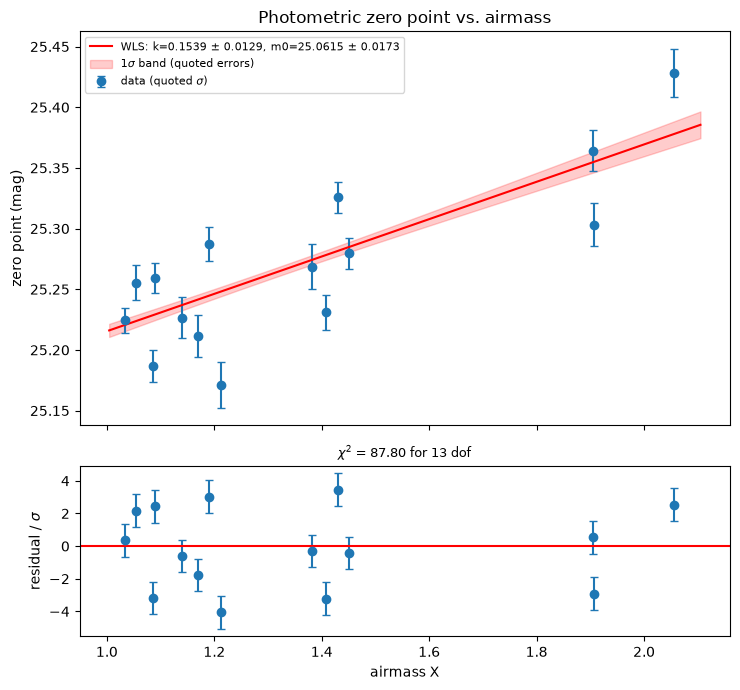

In [4]:
# 1a: your work here
"""
Extinction coefficient from zero point vs airmass:  m = k*X + m0

Usage:  python extinction_analysis.py [path/to/p1a_extinction.csv]
"""
import sys
import numpy as np
import pandas as pd
from scipy.stats import chi2
import matplotlib.pyplot as plt

path = "../../labs/midterm/data/cmewing2/p1a_extinction.csv"
d = pd.read_csv(path)
X = d["airmass"].values
m = d["zeropoint_mag"].values
s = d["sigma_quoted_mag"].values
N = len(X)
nu = N - 2  # 2 fitted parameters

# ---------------------------------------------------------------
# 1. Weighted least squares, quoted errors only
# ---------------------------------------------------------------
A = np.vstack([X, np.ones(N)]).T          # design matrix [X, 1]
W = np.diag(1.0 / s**2)                    # weights = 1/sigma^2
C = np.linalg.inv(A.T @ W @ A)             # parameter covariance (unscaled)
k, m0 = C @ A.T @ W @ m
ek, em0 = np.sqrt(np.diag(C))
corr = C[0, 1] / (ek * em0)

print("=== 1. Weighted least squares (quoted errors) ===")
print(f"k  = {k:.5f} +/- {ek:.5f} mag/airmass")
print(f"m0 = {m0:.5f} +/- {em0:.5f} mag")
print(f"corr(k, m0) = {corr:.3f}")

# ---------------------------------------------------------------
# 2. np.polyfit: note w = 1/sigma (NOT 1/sigma^2)
# ---------------------------------------------------------------
p_scaled, C_scaled = np.polyfit(X, m, 1, w=1.0 / s, cov=True)
p_unsc, C_unsc = np.polyfit(X, m, 1, w=1.0 / s, cov="unscaled")

print("\n=== 2. np.polyfit ===")
print(f"cov=True        : k = {p_scaled[0]:.5f} +/- {np.sqrt(C_scaled[0, 0]):.5f}")
print(f"cov='unscaled'  : k = {p_unsc[0]:.5f} +/- {np.sqrt(C_unsc[0, 0]):.5f}")

# ---------------------------------------------------------------
# 3. Chi-square and its probability
# ---------------------------------------------------------------
res = m - (k * X + m0)
chisq = np.sum((res / s) ** 2)
chisq_red = chisq / nu
p_large = chi2.sf(chisq, nu)    # P(chi2 >= observed)
p_small = chi2.cdf(chisq, nu)   # P(chi2 <= observed)
lo, hi = chi2.ppf([0.025, 0.975], nu)

print("\n=== 3. Goodness of fit ===")
print(f"chi2 = {chisq:.3f}, dof = {nu}, chi2_red = {chisq_red:.3f}")
print(f"P(chi2 >= obs) = {p_large:.3e}")
print(f"P(chi2 <= obs) = {p_small:.12f}")
print(f"95% interval for chi2 with {nu} dof: [{lo:.2f}, {hi:.2f}]")
print("normalized residuals:", np.round(res / s, 2))

# ---------------------------------------------------------------
# 4. Error bar to quote: rescale by sqrt(chi2_red)
# ---------------------------------------------------------------
ek_scaled = ek * np.sqrt(chisq_red)
print("\n=== 4. Error bar to quote ===")
print(f"scale factor sqrt(chi2_red) = {np.sqrt(chisq_red):.3f}")
print(f"k = {k:.4f} +/- {ek_scaled:.4f} mag/airmass (scaled)")

# Check for model misfit: does a quadratic term help?
pq = np.polyfit(X, m, 2, w=1.0 / s)
chisq_quad = np.sum(((m - np.polyval(pq, X)) / s) ** 2)
print(f"quadratic fit: chi2 = {chisq_quad:.2f}  (drop of {chisq - chisq_quad:.2f} for 1 extra parameter)")
print(f"corr(residual/sigma, X) = {np.corrcoef(res / s, X)[0, 1]:.3f}")

# ---------------------------------------------------------------
# Plot
# ---------------------------------------------------------------
fig, ax = plt.subplots(2, 1, figsize=(7.5, 7), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1.3]})
xx = np.linspace(X.min() - 0.03, X.max() + 0.05, 200)
band = np.sqrt(C[0, 0] * xx**2 + 2 * C[0, 1] * xx + C[1, 1])

ax[0].errorbar(X, m, yerr=s, fmt="o", capsize=3, label=r"data (quoted $\sigma$)")
ax[0].plot(xx, k * xx + m0, "r-",
           label=f"WLS: k={k:.4f} ± {ek:.4f}, m0={m0:.4f} ± {em0:.4f}")
ax[0].fill_between(xx, k * xx + m0 - band, k * xx + m0 + band,
                   color="r", alpha=0.2, label=r"1$\sigma$ band (quoted errors)")
ax[0].set_ylabel("zero point (mag)")
ax[0].set_title("Photometric zero point vs. airmass")
ax[0].legend(fontsize=8, loc="upper left")

ax[1].errorbar(X, res / s, yerr=1, fmt="o", capsize=3)
ax[1].axhline(0, color="r")
ax[1].set_ylabel(r"residual / $\sigma$")
ax[1].set_xlabel("airmass X")
ax[1].set_title(rf"$\chi^2$ = {chisq:.2f} for {nu} dof", fontsize=9)

plt.tight_layout()
plt.savefig("extinction_fit.png", dpi=150)
plt.show()

**ANSWER:**

*Since x^2 was one than*

### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [1]:
# 1b: your work here

"""
Cramer-Rao bound on a Gaussian centroid, compared with a quoted error.

Usage:  python centroid_crb.py [path/to/p1b_centroid.csv]
"""
import sys
import numpy as np
import pandas as pd

path = "../../labs/midterm/data/cmewing2/p1b_centroid.csv"
row = pd.read_csv(path).iloc[0]
sigma = row["psf_sigma_arcsec"]
N = int(row["n_photons"])
quoted = row["quoted_sigma_x0_arcsec"]

# ---------------------------------------------------------------
# 1. Cramer-Rao bound
#    ln L = -sum (x_i - x0)^2 / (2 sigma^2) + const
#    -d2 lnL / dx0^2 = N / sigma^2  ->  Fisher information I = N / sigma^2
#    sigma_x0 >= 1 / sqrt(I) = sigma / sqrt(N)
# ---------------------------------------------------------------
fisher = N / sigma**2
crb = 1.0 / np.sqrt(fisher)

print("=== 1. Cramer-Rao bound ===")
print(f"sigma_PSF = {sigma} arcsec, N = {N}")
print(f"Fisher information I = {fisher:.2f} arcsec^-2")
print(f"CRB: sigma_x0 >= {crb:.5f} arcsec")

# ---------------------------------------------------------------
# 2. Compare with the quoted error
# ---------------------------------------------------------------
print("\n=== 2. Quoted error vs bound ===")
print(f"quoted        = {quoted:.5f} arcsec")
print(f"quoted / CRB  = {quoted / crb:.3f}")
print(f"variance ratio (quoted^2 / CRB^2) = {(quoted / crb) ** 2:.3f}")
print("Possible for an unbiased estimator?", "YES" if quoted >= crb else "NO (below the bound)")

# What the quoted number would imply under each candidate mistake
N_implied = (sigma / quoted) ** 2          # photons needed to reach quoted error
sigma_implied = quoted * np.sqrt(N)        # PSF width that would give quoted error
print(f"\nImplied N (with true sigma)      = {N_implied:.0f}  ({N_implied / N:.2f} x actual N)")
print(f"Implied sigma (with true N)      = {sigma_implied:.4f} arcsec  ({sigma_implied / sigma:.3f} x true sigma)")
print(f"For comparison, sigma/N (wrong)  = {sigma / N:.5f} arcsec")

# ---------------------------------------------------------------
# 3. Monte Carlo: the sample mean attains the CRB
# ---------------------------------------------------------------
rng = np.random.default_rng(0)
n_trials = 200_000
x0_true = 0.0
photons = rng.normal(x0_true, sigma, size=(n_trials, N))
est = photons.mean(axis=1)

print("\n=== 3. Monte Carlo check (sample mean) ===")
print(f"scatter of sample mean over {n_trials} trials = {est.std():.5f} arcsec")
print(f"CRB                                          = {crb:.5f} arcsec")
print(f"fraction of trials with |error| < quoted     = {np.mean(np.abs(est - x0_true) < quoted):.3f}")
print(f"  (a true 1-sigma error would give 0.683; at the CRB it is "
      f"{np.mean(np.abs(est - x0_true) < crb):.3f})")
00

=== 1. Cramer-Rao bound ===
sigma_PSF = 1.07889 arcsec, N = 326
Fisher information I = 280.07 arcsec^-2
CRB: sigma_x0 >= 0.05975 arcsec

=== 2. Quoted error vs bound ===
quoted        = 0.03852 arcsec
quoted / CRB  = 0.645
variance ratio (quoted^2 / CRB^2) = 0.416
Possible for an unbiased estimator? NO (below the bound)

Implied N (with true sigma)      = 784  (2.41 x actual N)
Implied sigma (with true N)      = 0.6956 arcsec  (0.645 x true sigma)
For comparison, sigma/N (wrong)  = 0.00331 arcsec

=== 3. Monte Carlo check (sample mean) ===
scatter of sample mean over 200000 trials = 0.05962 arcsec
CRB                                          = 0.05975 arcsec
fraction of trials with |error| < quoted     = 0.480
  (a true 1-sigma error would give 0.683; at the CRB it is 0.683)


0

**ANSWER:**

*your answer goes here*

### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

=== 1. Best depth and curvature ===
grid minimum: depth = 2.0134 ppt, -2lnL = 119.393
window +/-0.1 ( 7 pts): best = 2.0129, f'' = 26.764, correct sigma = sqrt(2/f'') = 0.2734, classmate 1/sqrt(f'') = 0.1933
window +/-0.2 (15 pts): best = 2.0113, f'' = 26.914, correct sigma = sqrt(2/f'') = 0.2726, classmate 1/sqrt(f'') = 0.1928
window +/-0.3 (23 pts): best = 2.0084, f'' = 26.919, correct sigma = sqrt(2/f'') = 0.2726, classmate 1/sqrt(f'') = 0.1927
window +/-0.5 (37 pts): best = 2.0006, f'' = 26.922, correct sigma = sqrt(2/f'') = 0.2726, classmate 1/sqrt(f'') = 0.1927

best depth             = 2.008 ppt
correct sigma          = 0.2726 ppt
classmate's sigma      = 0.1927 ppt
ratio correct/classmate = 1.4142  (sqrt(2) = 1.4142)

=== 2. Delta(-2lnL) = 1 interval ===
interval: [1.7344, 2.2798] ppt about grid min 2.0134
minus side = 0.2790, plus side = 0.2664, asymmetry = -0.0126 ppt
half-width = 0.2727  vs curvature sigma = 0.2726

=== 3. Coverage ===
predicted coverage = erf(0.5000) = 0.52

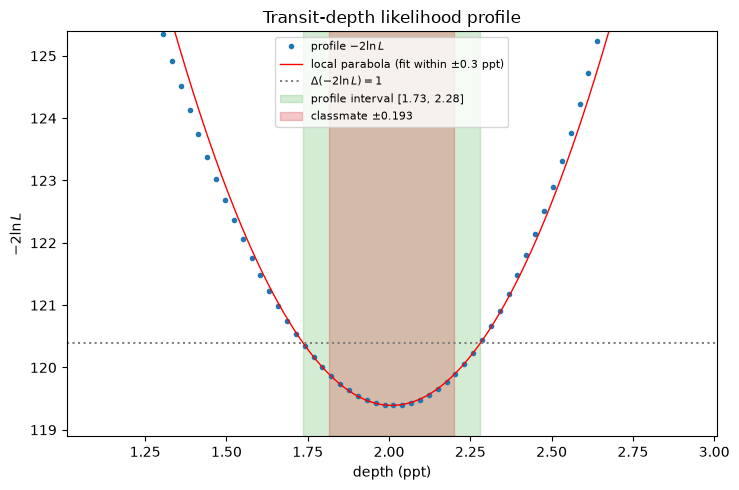

In [3]:
# 1c: your work here
"""
Transit-depth error bar from a -2lnL profile.
 
Usage:  python depth_profile.py [path/to/p1c_profile.csv]
"""
import sys
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.stats import norm
import matplotlib.pyplot as plt


path = "../../labs/midterm/data/cmewing2/p1c_profile.csv"
d = pd.read_csv(path)
x = d["depth_ppt"].values
f = d["minus2lnL"].values            # f = -2 ln L
 
# ---------------------------------------------------------------
# 1. Best depth and curvature error
#    Near the minimum f ~ (depth - best)^2 / sigma^2 + const
#    => f'' = 2/sigma^2  =>  sigma = sqrt(2 / f'')
#    The classmate's 1/sqrt(f'') is sigma/sqrt(2).
#    f is tabulated to 3 decimals, so differentiating the raw grid is noisy;
#    fit a local parabola instead (check several window sizes).
# ---------------------------------------------------------------
i0 = f.argmin()
print("=== 1. Best depth and curvature ===")
print(f"grid minimum: depth = {x[i0]:.4f} ppt, -2lnL = {f[i0]:.3f}")
 
for w in (0.1, 0.2, 0.3, 0.5):
    m = np.abs(x - x[i0]) <= w
    c2, c1, c0 = np.polyfit(x[m] - x[i0], f[m], 2)
    fpp = 2 * c2
    best = x[i0] - c1 / (2 * c2)
    print(f"window +/-{w:.1f} ({m.sum():2d} pts): best = {best:.4f}, f'' = {fpp:.3f}, "
          f"correct sigma = sqrt(2/f'') = {np.sqrt(2 / fpp):.4f}, "
          f"classmate 1/sqrt(f'') = {1 / np.sqrt(fpp):.4f}")
 
# adopt the +/-0.3 window as the working answer
m = np.abs(x - x[i0]) <= 0.3
c2, c1, c0 = np.polyfit(x[m] - x[i0], f[m], 2)
fpp = 2 * c2
best = x[i0] - c1 / (2 * c2)
sigma = np.sqrt(2 / fpp)
sigma_class = 1 / np.sqrt(fpp)
print(f"\nbest depth             = {best:.3f} ppt")
print(f"correct sigma          = {sigma:.4f} ppt")
print(f"classmate's sigma      = {sigma_class:.4f} ppt")
print(f"ratio correct/classmate = {sigma / sigma_class:.4f}  (sqrt(2) = {np.sqrt(2):.4f})")
 
# ---------------------------------------------------------------
# 2. Delta(-2lnL) = 1 interval read directly off the profile
#    (linear interpolation of the tabulated profile; no parabola assumed)
# ---------------------------------------------------------------
fmin = f[i0]
g = lambda t: np.interp(t, x, f) - fmin - 1.0
lo = brentq(g, x.min(), x[i0])
hi = brentq(g, x[i0], x.max())
print("\n=== 2. Delta(-2lnL) = 1 interval ===")
print(f"interval: [{lo:.4f}, {hi:.4f}] ppt about grid min {x[i0]:.4f}")
print(f"minus side = {x[i0] - lo:.4f}, plus side = {hi - x[i0]:.4f}, "
      f"asymmetry = {((hi - x[i0]) - (x[i0] - lo)):+.4f} ppt")
print(f"half-width = {(hi - lo) / 2:.4f}  vs curvature sigma = {sigma:.4f}")
 
# ---------------------------------------------------------------
# 3. Coverage of the classmate's +/- sigma_class interval
#    Interval is +/- sigma/sqrt(2) in units of the TRUE sigma -> |z| < 1/sqrt(2)
# ---------------------------------------------------------------
z = sigma_class / sigma
pred = 2 * norm.cdf(z) - 1
print("\n=== 3. Coverage ===")
print(f"predicted coverage = erf({z / np.sqrt(2):.4f}) = {pred:.4f}")
 
rng = np.random.default_rng(1)
truth = 2.0                                   # chosen true depth (ppt)
for n in (5000, 1_000_000):
    dhat = rng.normal(truth, sigma, n)        # fake best-fit depths
    cov_class = np.mean(np.abs(dhat - truth) < sigma_class)
    cov_right = np.mean(np.abs(dhat - truth) < sigma)
    err = np.sqrt(cov_class * (1 - cov_class) / n)
    print(f"n = {n:>9,}: classmate coverage = {cov_class:.4f} +/- {err:.4f}, "
          f"correct-sigma coverage = {cov_right:.4f}")
 
# ---------------------------------------------------------------
# Plot
# ---------------------------------------------------------------
xx = np.linspace(x.min(), x.max(), 400)
parab = np.polyval([c2, c1, c0], xx - x[i0])
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(x, f, "o", ms=3, label=r"profile $-2\ln L$")
ax.plot(xx, parab, "r-", lw=1, label=f"local parabola (fit within ±0.3 ppt)")
ax.axhline(fmin + 1, color="gray", ls=":", label=r"$\Delta(-2\ln L)=1$")
ax.axvspan(lo, hi, color="C2", alpha=0.2, label=f"profile interval [{lo:.2f}, {hi:.2f}]")
ax.axvspan(best - sigma_class, best + sigma_class, color="C3", alpha=0.25,
           label=f"classmate ±{sigma_class:.3f}")
ax.set_xlim(best - 1.0, best + 1.0)
ax.set_ylim(fmin - 0.5, fmin + 6)
ax.set_xlabel("depth (ppt)")
ax.set_ylabel(r"$-2\ln L$")
ax.set_title("Transit-depth likelihood profile")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("depth_profile.png", dpi=150)
plt.show()

**ANSWER:**

*your answer goes here*

### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

=== 1. Median and 16-84 percentile bars ===
N samples = 8000
M2 = 7.2378 +2.2766 / -1.7446 Msun

=== 2. Classmates' quantities ===

------------------------------------------------------------------
(i) VARIANCE
------------------------------------------------------------------
  What it is   : the spread of the samples multiplied by itself (sigma^2)
  Their number : 4.54961
  Units        : Msun^2 (solar masses SQUARED, not solar masses)
  Compare with : posterior std (sigma) = 2.1330 Msun
  Factor off   : numerically 2.133 x sigma (too big); units also wrong
  Verdict      : NOT an error bar on a mass: wrong units, so it cannot be compared to M2

------------------------------------------------------------------
(ii) 84th MINUS 16th PERCENTILE
------------------------------------------------------------------
  What it is   : the FULL width of the range holding the middle 68% of samples
  Their number : 4.0212
  Units        : Msun
  Compare with : proper +/- bar (half of that width)

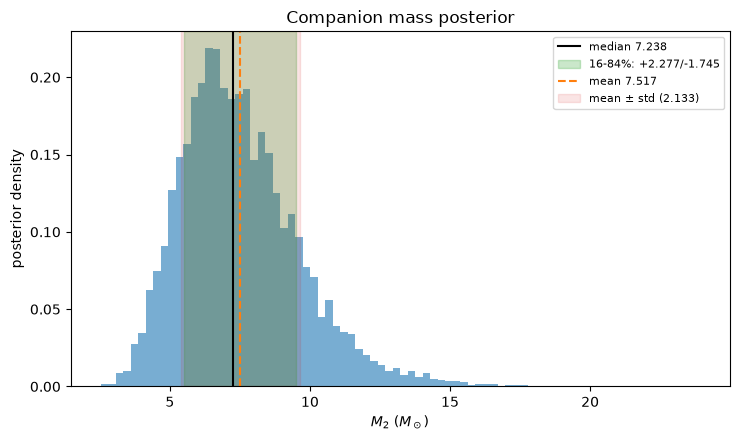

In [7]:
# 1d: your work here
from scipy.stats import skew

path = "../../labs/midterm/data/cmewing2/p1d_mass_samples.csv"
M = pd.read_csv(path)["M2_Msun"].values
N = len(M)
 
# ---------------------------------------------------------------
# 1. Median with 16th-84th percentile error bars
# ---------------------------------------------------------------
p16, p50, p84 = np.percentile(M, [16, 50, 84])
minus, plus = p50 - p16, p84 - p50
print("=== 1. Median and 16-84 percentile bars ===")
print(f"N samples = {N}")
print(f"M2 = {p50:.4f} +{plus:.4f} / -{minus:.4f} Msun")
 
# ---------------------------------------------------------------
# 2. The three classmates' numbers
# ---------------------------------------------------------------
sd = M.std(ddof=1)
var = M.var(ddof=1)
width = p84 - p16
sem = sd / np.sqrt(N)
 
half = width / 2   # half of the 68% interval: the proper "+/-" size for a symmetric posterior
 
 
def show(label, what, value, units, ref_name, ref_value, factor_text, verdict):
    bar = "-" * 66
    print(bar)
    print(label)
    print(bar)
    print(f"  What it is   : {what}")
    print(f"  Their number : {value}")
    print(f"  Units        : {units}")
    print(f"  Compare with : {ref_name} = {ref_value}")
    print(f"  Factor off   : {factor_text}")
    print(f"  Verdict      : {verdict}")
    print()
 
 
print("\n=== 2. Classmates' quantities ===\n")
show("(i) VARIANCE",
     "the spread of the samples multiplied by itself (sigma^2)",
     f"{var:.5f}",
     "Msun^2 (solar masses SQUARED, not solar masses)",
     "posterior std (sigma)", f"{sd:.4f} Msun",
     f"numerically {var / sd:.3f} x sigma "
     f"({'too small' if var < sd else 'too big'}); units also wrong",
     "NOT an error bar on a mass: wrong units, so it cannot be compared to M2")
show("(ii) 84th MINUS 16th PERCENTILE",
     "the FULL width of the range holding the middle 68% of samples",
     f"{width:.4f}",
     "Msun",
     "proper +/- bar (half of that width)", f"{half:.4f} Msun",
     f"{width / half:.1f} x too big (a +/- bar covers only half the width each side)",
     "right quantity, wrong use: take each half separately (median-P16, P84-median)")
show("(iii) STD / sqrt(N)",
     "how precisely the AVERAGE of the samples is pinned down (not the uncertainty on M2)",
     f"{sem:.5f}",
     "Msun",
     "posterior std (sigma)", f"{sd:.4f} Msun",
     f"{sd / sem:.1f} x too small (= sqrt(N) = sqrt({N}))",
     "shrinks toward 0 with more samples, but the true uncertainty does not")
 
# ---------------------------------------------------------------
# 3. Is a symmetric +/- bar appropriate?
# ---------------------------------------------------------------
print("\n=== 3. Symmetry ===")
print(f"plus / minus bar ratio = {plus / minus:.3f}   (1.0 for a symmetric posterior)")
print(f"mean = {M.mean():.4f}, median = {p50:.4f}, mean - median = {M.mean() - p50:+.4f} Msun")
print(f"sample skewness = {skew(M):+.3f}   (0 for a symmetric posterior)")
print(f"mean +/- std  covers [{M.mean() - sd:.4f}, {M.mean() + sd:.4f}] -> "
      f"fraction of samples inside = {np.mean(np.abs(M - M.mean()) < sd):.3f}")
print(f"P(M < median - std) = {np.mean(M < p50 - sd):.3f},  P(M > median + std) = {np.mean(M > p50 + sd):.3f}")
print(f"min sample = {M.min():.4f} Msun; mean - 2*std = {M.mean() - 2 * sd:.4f}"
      f"  -> {'goes below zero (unphysical)' if M.mean() - 2 * sd < 0 else 'stays positive'}")
 
# ---------------------------------------------------------------
# Plot
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(M, bins=80, density=True, color="C0", alpha=0.6)
ax.axvline(p50, color="k", label=f"median {p50:.3f}")
ax.axvspan(p16, p84, color="C2", alpha=0.25, label=f"16-84%: +{plus:.3f}/-{minus:.3f}")
ax.axvline(M.mean(), color="C1", ls="--", label=f"mean {M.mean():.3f}")
ax.axvspan(M.mean() - sd, M.mean() + sd, color="C3", alpha=0.12, label=f"mean ± std ({sd:.3f})")
ax.set_xlabel(r"$M_2$ ($M_\odot$)")
ax.set_ylabel("posterior density")
ax.set_title("Companion mass posterior")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("mass_posterior.png", dpi=150)
plt.show()

**ANSWER:**

* The symmetric bar is not appropriate because of the right skewed graph. A ± σ bar implies about 16% of samples fall beyond each end. Here it’s 17.6% above and 10.5% below, so the bar would be wrong about the odds of being high versus low. *

### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

using columns: slope = 'slope', intercept = 'intercept'

=== 1. Slope error bars ===
marginal (intercept marginalized)      sigma_a = 0.05390
classmate (intercept fixed), analytic  sigma_a|b = sigma_a*sqrt(1-rho^2) = 0.02669
  check: residual after regressing on b                  = 0.02669
  check: thin slice |b - b_best| < 0.1 sigma_b (480 samples) = 0.02765

=== 2. Ratio and correlation ===
correlation coefficient rho = -0.8688
ratio marginal / fixed      = 2.0196
theory 1/sqrt(1-rho^2)      = 2.0196

rho    ratio = 1/sqrt(1-rho^2)
0.00     1.00
0.30     1.05
0.50     1.15
0.70     1.40
0.90     2.29
0.95     3.20
0.99     7.09


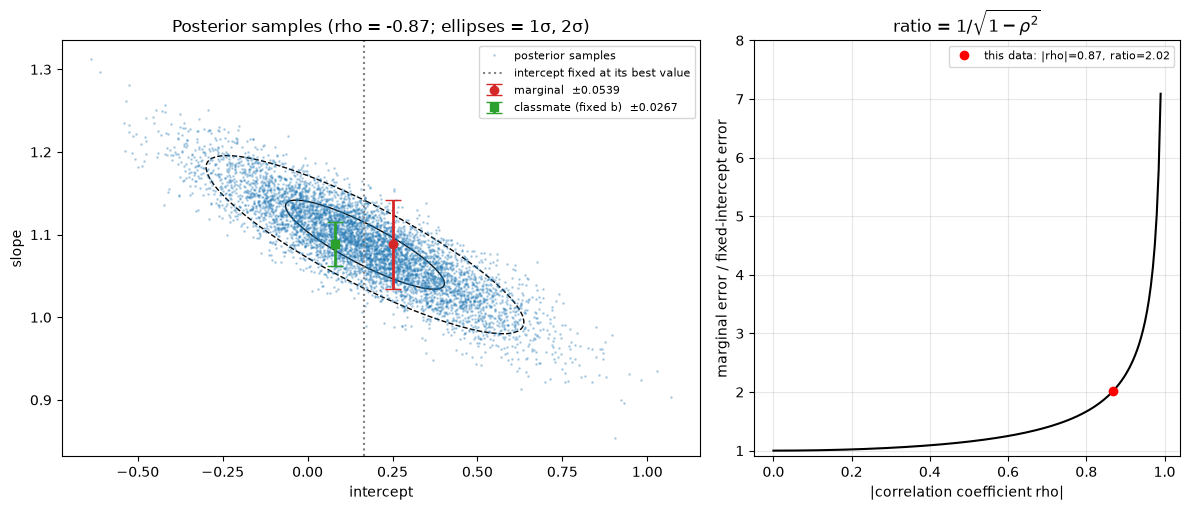

In [9]:
# 1e: your work here
"""
Slope error: intercept fixed (classmate) vs intercept marginalized.
 
Usage:  python slope_intercept.py [path/to/p1e_slope_intercept_samples.csv]
 
Columns: it looks for names containing 'slope' and 'inter'; if it can't find
them, it uses the first two columns as (slope, intercept).
"""

from matplotlib.patches import Ellipse
 
path = "../../labs/midterm/data/cmewing2/p1e_slope_intercept_samples.csv"
df = pd.read_csv(path)
cols = {c.lower(): c for c in df.columns}
slope_col = next((cols[c] for c in cols if "slope" in c), df.columns[0])
inter_col = next((cols[c] for c in cols if "inter" in c), df.columns[1])
print(f"using columns: slope = '{slope_col}', intercept = '{inter_col}'")
 
a = df[slope_col].values       # slope
b = df[inter_col].values       # intercept
N = len(a)
 
# ---------------------------------------------------------------
# 1. Marginal and fixed-intercept slope errors
# ---------------------------------------------------------------
sig_marg = a.std(ddof=1)                       # intercept marginalized over
sig_b = b.std(ddof=1)
rho = np.corrcoef(a, b)[0, 1]
 
# Classmate: slope spread with the intercept held at its best value.
# (a) analytic conditional width for a Gaussian posterior: sigma_a * sqrt(1 - rho^2)
sig_fixed = sig_marg * np.sqrt(1 - rho**2)
# (b) check straight from the samples: residual spread of the slope after
#     removing its linear dependence on the intercept (= slope at fixed intercept)
beta = np.cov(a, b)[0, 1] / b.var(ddof=1)
sig_fixed_resid = (a - beta * b).std(ddof=2)
# (c) second check: slope spread in a thin slice of intercept around its best value
b_best = np.median(b)
a_best = np.median(a)
sl = np.abs(b - b_best) < 0.1 * sig_b
sig_fixed_slice = a[sl].std(ddof=1)
 
print("\n=== 1. Slope error bars ===")
print(f"marginal (intercept marginalized)      sigma_a = {sig_marg:.5f}")
print(f"classmate (intercept fixed), analytic  sigma_a|b = sigma_a*sqrt(1-rho^2) = {sig_fixed:.5f}")
print(f"  check: residual after regressing on b                  = {sig_fixed_resid:.5f}")
print(f"  check: thin slice |b - b_best| < 0.1 sigma_b ({sl.sum()} samples) = {sig_fixed_slice:.5f}")
 
# ---------------------------------------------------------------
# 2. Ratio and its dependence on the correlation coefficient
#    marginal / fixed = 1 / sqrt(1 - rho^2)
# ---------------------------------------------------------------
ratio = sig_marg / sig_fixed
print("\n=== 2. Ratio and correlation ===")
print(f"correlation coefficient rho = {rho:+.4f}")
print(f"ratio marginal / fixed      = {ratio:.4f}")
print(f"theory 1/sqrt(1-rho^2)      = {1 / np.sqrt(1 - rho**2):.4f}")
print("\nrho    ratio = 1/sqrt(1-rho^2)")
for r in (0.0, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99):
    print(f"{r:4.2f}   {1 / np.sqrt(1 - r**2):6.2f}")
 
# ---------------------------------------------------------------
# Plot
# ---------------------------------------------------------------
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
 
ax.plot(b, a, ".", ms=2, alpha=0.25, color="C0", label="posterior samples")
cov = np.cov(b, a)                                  # (intercept, slope)
vals, vecs = np.linalg.eigh(cov)
ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
for k, ls in ((1, "-"), (2, "--")):
    ax.add_patch(Ellipse((b.mean(), a.mean()), 2 * k * np.sqrt(vals[1]), 2 * k * np.sqrt(vals[0]),
                         angle=ang, fill=False, color="k", ls=ls, lw=1))
ax.axvline(b_best, color="gray", ls=":", label="intercept fixed at its best value")
dx = 0.05 * (b.max() - b.min())
ax.errorbar([b_best + dx], [a_best], yerr=sig_marg, fmt="o", color="C3", capsize=6, lw=2,
            label=f"marginal  ±{sig_marg:.4f}")
ax.errorbar([b_best - dx], [a_best], yerr=sig_fixed, fmt="s", color="C2", capsize=6, lw=2,
            label=f"classmate (fixed b)  ±{sig_fixed:.4f}")
ax.set_xlabel("intercept")
ax.set_ylabel("slope")
ax.set_title(f"Posterior samples (rho = {rho:+.2f}; ellipses = 1σ, 2σ)")
ax.legend(fontsize=8, loc="best")
 
rr = np.linspace(0, 0.99, 200)
ax2.plot(rr, 1 / np.sqrt(1 - rr**2), "k-")
ax2.plot([abs(rho)], [ratio], "ro", label=f"this data: |rho|={abs(rho):.2f}, ratio={ratio:.2f}")
ax2.set_xlabel("|correlation coefficient rho|")
ax2.set_ylabel("marginal error / fixed-intercept error")
ax2.set_title(r"ratio = $1/\sqrt{1-\rho^2}$")
ax2.set_ylim(0.9, 8)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)
 
plt.tight_layout()
plt.savefig("slope_intercept.png", dpi=150)
plt.show()
 

**ANSWER:**

*It is right only when the intercept is truly known.*

## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

N = 250, median(mB - mu) = -19.359 mag (absorbed into M)
robust scatter of residuals (1.4826*MAD) = 0.304 mag
quick standardization (unweighted): alpha = +0.130 mag per unit x1, beta = +2.930, scatter = 0.102 mag
candidate outliers (standardized residual > 4 sigma): rows [19, 68, 70]

=== Raw trends (unweighted OLS) ===
r vs x1           : slope = -0.1770 +/- 0.0192 (all);  -0.1758 +/- 0.0181 (candidate outliers removed)
r vs c            : slope = +2.8749 +/- 0.1613 (all);  +2.9612 +/- 0.1384 (candidate outliers removed)
r vs host_logmass : slope = +0.1029 +/- 0.0261 (all);  +0.1147 +/- 0.0249 (candidate outliers removed)

=== Do x1 and c correlate with host mass? ===
corr(x1, host_logmass) = -0.413
corr(c , host_logmass) = +0.176
mean x1: high-mass hosts = -0.408, low-mass hosts = +0.251
mean c : high-mass hosts = +0.0012, low-mass hosts = -0.0160

raw     mean residual: high - low mass = +0.1245 mag
standardized mean residual: high - low mass = -0.0117 mag

=== Largest positive resi

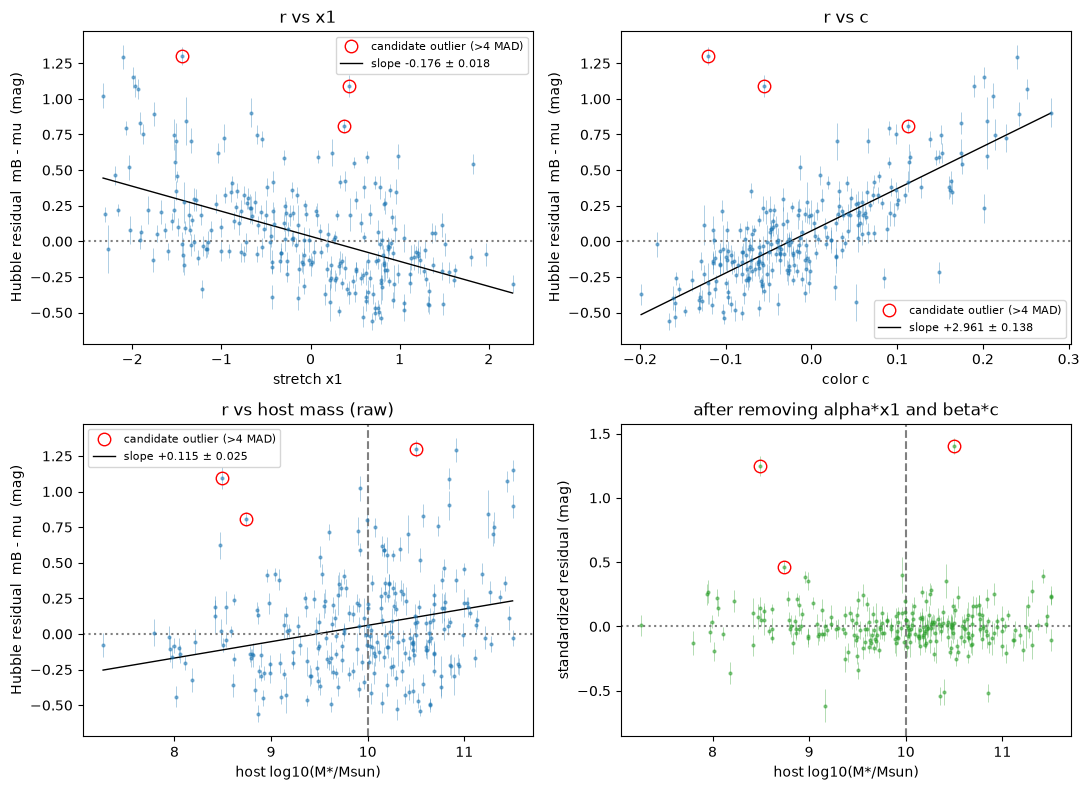

In [11]:
# 2a: your work here
"""
Pantheon+ SNe Ia: Hubble residuals vs stretch (x1), color (c) and host mass. ChatPGT automatically used OLS model fit.

Usage:  python sne_residuals.py [path/to/p2_pantheon_sne.csv]

Residual definition:  r = mB - mu(z) - median(mB - mu(z))
  (the median is removed because the absolute magnitude M absorbs any constant offset,
   including the choice of H0).  Positive r = fainter than the typical SN at that z.
"""
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path =  "../../labs/midterm/data/cmewing2/p2_pantheon_sne.csv"
df = pd.read_csv(path)
z = df["z"].values
mB, mB_err = df["mB"].values, df["mB_err"].values
x1, c = df["x1"].values, df["c"].values
logM = df["host_logmass"].values

# ---------------------------------------------------------------
# Distance modulus, flat LCDM, H0 = 70, Om = 0.3
# ---------------------------------------------------------------
try:
    from astropy.cosmology import FlatLambdaCDM
    mu = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
except ImportError:                                   # fallback: integrate by hand
    from scipy.integrate import quad
    cL, H0, Om = 299792.458, 70.0, 0.3
    E = lambda zz: np.sqrt(Om * (1 + zz) ** 3 + 1 - Om)
    dc = np.array([quad(lambda t: 1 / E(t), 0, zi)[0] for zi in z]) * cL / H0   # Mpc
    mu = 5 * np.log10((1 + z) * dc * 1e6 / 10)

# peculiar-velocity error on mu (mag), added to the photometric error for plotting
sig_pec = 5 / np.log(10) * 250.0 / (299792.458 * z)
sig_tot = np.sqrt(mB_err**2 + sig_pec**2)

# ---------------------------------------------------------------
# 1. Hubble residuals
# ---------------------------------------------------------------
r0 = mB - mu
r = r0 - np.median(r0)
print(f"N = {len(r)}, median(mB - mu) = {np.median(r0):.3f} mag (absorbed into M)")
print(f"robust scatter of residuals (1.4826*MAD) = {1.4826 * np.median(np.abs(r - np.median(r))):.3f} mag")


def ols_slope(x, y, w=None):
    """slope and error of y = a + b x (optionally weighted by 1/sigma^2)."""
    A = np.vstack([np.ones_like(x), x]).T
    W = np.diag(1 / w**2) if w is not None else np.eye(len(x))
    C = np.linalg.inv(A.T @ W @ A)
    p = C @ A.T @ W @ y
    res = y - A @ p
    s2 = np.sum(res**2) / (len(x) - 2) if w is None else np.sum((res / w) ** 2) / (len(x) - 2)
    return p[1], np.sqrt(C[1, 1] * (s2 if w is None else s2))


# Quick standardization r = M' - alpha*x1 + beta*c with iterative 3-sigma clipping.
# Outliers are flagged on the STANDARDIZED residual: in the raw residuals the large
# spread from x1 and c can hide a 1-mag contaminant.
A = np.vstack([np.ones_like(x1), -x1, c]).T
use = np.ones(len(r), bool)
for _ in range(6):
    p, *_ = np.linalg.lstsq(A[use], r[use], rcond=None)
    rs = r - A @ p
    s_std = 1.4826 * np.median(np.abs(rs[use] - np.median(rs[use])))
    use = np.abs(rs) < 3 * s_std
alpha, beta = p[1], p[2]
outlier = rs > 4 * s_std                              # candidate contaminants (too faint)
keep = ~outlier
print(f"quick standardization (unweighted): alpha = {alpha:+.3f} mag per unit x1, "
      f"beta = {beta:+.3f}, scatter = {s_std:.3f} mag")
print(f"candidate outliers (standardized residual > 4 sigma): rows {np.where(outlier)[0].tolist()}")
print("\n=== Raw trends (unweighted OLS) ===")
for name, x in (("x1", x1), ("c", c), ("host_logmass", logM)):
    b_all, e_all = ols_slope(x, r)
    b_k, e_k = ols_slope(x[keep], r[keep])
    print(f"r vs {name:13s}: slope = {b_all:+.4f} +/- {e_all:.4f} (all);  "
          f"{b_k:+.4f} +/- {e_k:.4f} (candidate outliers removed)")

# ---------------------------------------------------------------
# 3. Why the raw host-mass trend need not have the sign of gamma
#    x1 and c themselves correlate with host mass.
# ---------------------------------------------------------------
print("\n=== Do x1 and c correlate with host mass? ===")
hi, lo = logM > 10, logM <= 10
print(f"corr(x1, host_logmass) = {np.corrcoef(x1[keep], logM[keep])[0, 1]:+.3f}")
print(f"corr(c , host_logmass) = {np.corrcoef(c[keep], logM[keep])[0, 1]:+.3f}")
print(f"mean x1: high-mass hosts = {x1[hi & keep].mean():+.3f}, low-mass hosts = {x1[lo & keep].mean():+.3f}")
print(f"mean c : high-mass hosts = {c[hi & keep].mean():+.4f}, low-mass hosts = {c[lo & keep].mean():+.4f}")

# compare the raw and standardized high-mass minus low-mass offsets
print(f"\nraw     mean residual: high - low mass = {r[hi & keep].mean() - r[lo & keep].mean():+.4f} mag")
print(f"standardized mean residual: high - low mass = {rs[hi & keep].mean() - rs[lo & keep].mean():+.4f} mag")

# ---------------------------------------------------------------
# 4. Candidate contaminants: large POSITIVE residuals (fainter)
# ---------------------------------------------------------------
print("\n=== Largest positive residuals (candidate contaminants) ===")
order = np.argsort(-rs)[:8]
print("row   z     raw r   standardized   (std/scatter)   x1      c")
for i in order:
    flag = "  <-- flagged" if outlier[i] else ""
    print(f"{i:3d}  {z[i]:.3f}  {r[i]:+.3f}   {rs[i]:+.3f}        {rs[i] / s_std:6.1f}       {x1[i]:+.2f}  {c[i]:+.3f}{flag}")

# ---------------------------------------------------------------
# Plots
# ---------------------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
panels = [(x1, "stretch x1", "r vs x1"), (c, "color c", "r vs c"),
          (logM, "host log10(M*/Msun)", "r vs host mass (raw)")]
for ax, (x, xl, t) in zip(axs.flat, panels):
    ax.errorbar(x, r, yerr=sig_tot, fmt=".", ms=4, alpha=0.5, color="C0", elinewidth=0.5)
    ax.plot(x[outlier], r[outlier], "ro", mfc="none", ms=9, label="candidate outlier (>4 MAD)")
    b, e = ols_slope(x[keep], r[keep])
    xx = np.linspace(x.min(), x.max(), 50)
    ax.plot(xx, np.median(r[keep]) + b * (xx - np.mean(x[keep])) + (np.mean(r[keep]) - np.median(r[keep])),
            "k-", lw=1, label=f"slope {b:+.3f} ± {e:.3f}")
    ax.axhline(0, color="gray", ls=":")
    ax.set_xlabel(xl)
    ax.set_ylabel("Hubble residual  mB - mu  (mag)")
    ax.set_title(t)
    ax.legend(fontsize=8)
axs[1, 0].axvline(10, color="gray", ls="--")

ax = axs[1, 1]
ax.errorbar(logM, rs, yerr=sig_tot, fmt=".", ms=4, alpha=0.5, color="C2", elinewidth=0.5)
ax.plot(logM[outlier], rs[outlier], "ro", mfc="none", ms=9)
ax.axvline(10, color="gray", ls="--")
ax.axhline(0, color="gray", ls=":")
ax.set_xlabel("host log10(M*/Msun)")
ax.set_ylabel("standardized residual (mag)")
ax.set_title("after removing alpha*x1 and beta*c")
plt.tight_layout()
plt.savefig("sne_residuals.png", dpi=150)
plt.show()

N = 250 supernovae; 135 in high-mass hosts (logM > 10)

--- A: no step, no outlier model: -2lnL = -135.77
  M          = -19.2901 +/- 0.0116
  alpha      = +0.1439 +/- 0.0113
  beta       = +2.7350 +/- 0.1268
  sigma_int  = 0.1602 +/- 0.0095 mag

--- B: with step, no outlier model: -2lnL = -137.13
  M          = -19.2754 +/- 0.0171
  alpha      = +0.1484 +/- 0.0119
  beta       = +2.7419 +/- 0.1265
  gamma      = -0.0284 +/- 0.0244
  sigma_int  = 0.1592 +/- 0.0095 mag

--- C: no step, outlier mixture: -2lnL = -259.29
  M          = -19.3007 +/- 0.0082
  alpha      = +0.1378 +/- 0.0079
  beta       = +2.9095 +/- 0.0895
  sigma_int  = 0.0737 +/- 0.0112 mag
  f_outlier  = 0.0638  (about 16.0 of 250 SNe)
  Delta      = 0.200 +/- 0.000 mag
  s_out      = 0.545 mag

--- D: step + outlier mixture  (preferred): -2lnL = -257.83
  M          = -19.3050 +/- 0.0116
  alpha      = +0.1356 +/- 0.0085
  beta       = +2.9151 +/- 0.0898
  gamma      = +0.0097 +/- 0.0171
  sigma_int  = 0.0758 +/- 0.0110

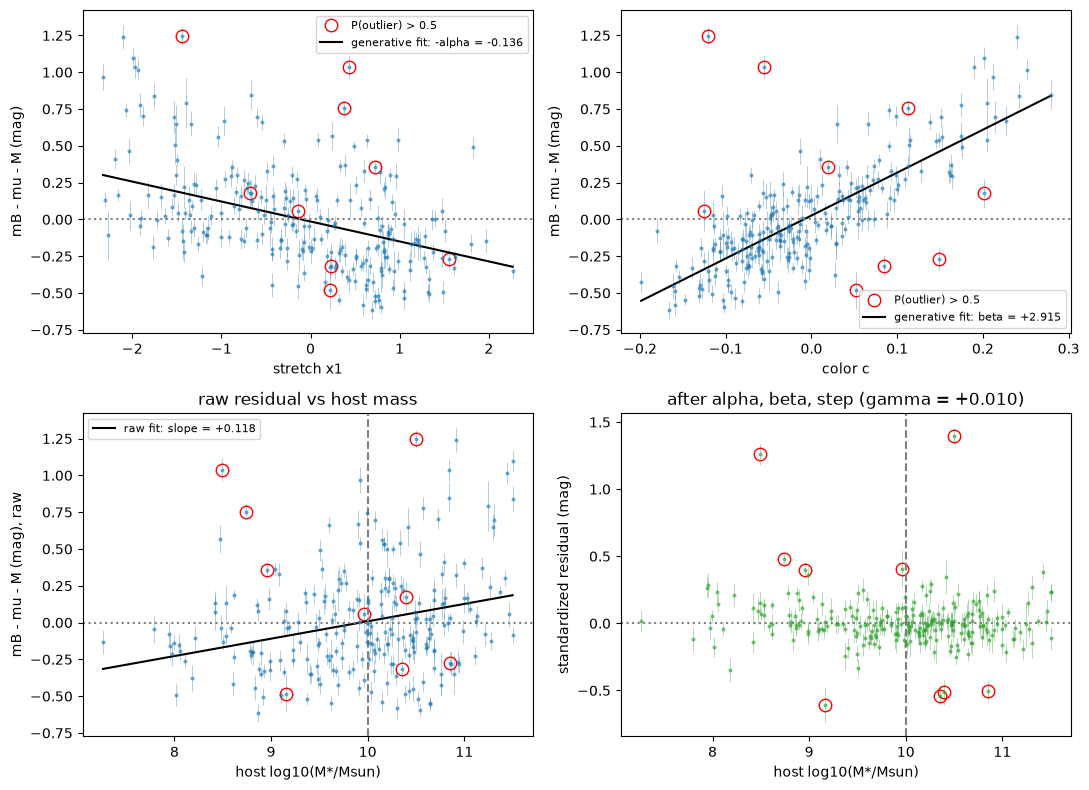

In [15]:
"""
Generative-model fit of the Tripp relation to Pantheon+ SNe Ia (no OLS).
 
Generative story for supernova i
    true corrected brightness:  mB* + alpha*x1* - beta*c*  =  M + mu(z_i) + gamma*theta_i + eps_i
        eps_i ~ N(0, sigma_int^2)                     (intrinsic scatter)
    observed (mB, x1, c) = true + noise,  noise ~ N(0, Sigma_i)   (3x3 covariance from the light-curve fit)
    redshift also scatters mu by sigma_pec,i             (peculiar velocities, 250 km/s)
Marginalizing the true x1*, c* (flat priors) gives, for the observed values,
    r_i = mB_i + alpha*x1_i - beta*c_i - mu(z_i) - gamma*theta_i
    r_i ~ N(M, V_i),   V_i = sigma_int^2 + sigma_pec,i^2 + v^T Sigma_i v,   v = (1, alpha, -beta)
V_i depends on alpha and beta, so the ln(V_i) term in the likelihood matters (this is
what OLS cannot do).
 
Contaminants: a mixture with an "outlier" component
    r_i ~ (1-f) N(M, V_i) + f N(M + Delta, V_i + s_out^2),    Delta > 0 (fainter)
The posterior probability that each SN is an outlier comes out of the fit.
 
theta_i = 1 if host_logmass > 10 else 0.
 
Usage:  python sne_generative.py [path/to/p2_pantheon_sne.csv]
Errors: inverse Hessian of -2lnL at the best fit; gamma also by profile likelihood.
"""

import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt
 
path =  "../../labs/midterm/data/cmewing2/p2_pantheon_sne.csv"
df = pd.read_csv(path)
z = df["z"].values
mB, x1, c = df["mB"].values, df["x1"].values, df["c"].values
logM = df["host_logmass"].values
theta = (logM > 10).astype(float)
N = len(z)
 
# ---- distance modulus (flat LCDM, H0 = 70, Om = 0.3) -------------------------
try:
    from astropy.cosmology import FlatLambdaCDM
    mu = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
except ImportError:
    from scipy.integrate import quad
    cL, H0, Om = 299792.458, 70.0, 0.3
    E = lambda zz: np.sqrt(Om * (1 + zz) ** 3 + 1 - Om)
    dc = np.array([quad(lambda t: 1 / E(t), 0, zi)[0] for zi in z]) * cL / H0
    mu = 5 * np.log10((1 + z) * dc * 1e6 / 10)
 
sig_pec2 = (5 / np.log(10) * 250.0 / (299792.458 * z)) ** 2
 
# ---- per-SN 3x3 covariance of (mB, x1, c) -----------------------------------
S = np.zeros((N, 3, 3))
S[:, 0, 0] = df["mB_err"] ** 2
S[:, 1, 1] = df["x1_err"] ** 2
S[:, 2, 2] = df["c_err"] ** 2
S[:, 0, 1] = S[:, 1, 0] = df["cov_mB_x1"]
S[:, 0, 2] = S[:, 2, 0] = df["cov_mB_c"]
S[:, 1, 2] = S[:, 2, 1] = df["cov_x1_c"]
 
names = ["M", "alpha", "beta", "gamma", "ln_sig_int", "logit_f", "Delta", "ln_s_out"]
 
 
def unpack(p, with_step=True, with_out=True):
    M, a, b, g, lsi, lf, D, lso = p
    if not with_step:
        g = 0.0
    return M, a, b, g, np.exp(lsi), 1 / (1 + np.exp(-lf)), D, np.exp(lso)
 
 
def parts(p, with_step=True, with_out=True):
    M, a, b, g, sint, f, D, so = unpack(p, with_step, with_out)
    v = np.stack([np.ones(N), a * np.ones(N), -b * np.ones(N)], axis=1)
    V = sint**2 + sig_pec2 + np.einsum("ni,nij,nj->n", v, S, v)
    r = mB + a * x1 - b * c - mu - g * theta
    return r, V, M, f, D, so
 
 
def m2lnL(p, with_step=True, with_out=True):
    r, V, M, f, D, so = parts(p, with_step, with_out)
    if with_out:
        if not (0.2 < D < 4 and 0.01 < so < 2):
            return 1e10
        good = np.log(1 - f) - 0.5 * np.log(2 * np.pi * V) - 0.5 * (r - M) ** 2 / V
        Vo = V + so**2
        bad = np.log(f) - 0.5 * np.log(2 * np.pi * Vo) - 0.5 * (r - M - D) ** 2 / Vo
        return -2 * np.sum(np.logaddexp(good, bad))
    return -2 * np.sum(-0.5 * np.log(2 * np.pi * V) - 0.5 * (r - M) ** 2 / V)
 
 
def fit(with_step=True, with_out=True, fix=None):
    """maximize the likelihood; fix = {index: value} holds parameters fixed (for profiles)."""
    fix = fix or {}
    free = [i for i in range(8) if i not in fix and
            not (i == 3 and not with_step) and not (i in (5, 6, 7) and not with_out)]
    base = np.array([-19.36, 0.13, 2.9, -0.05, np.log(0.1), -4.0, 1.0, np.log(0.3)])
    for i, v in fix.items():
        base[i] = v
 
    def obj(q):
        p = base.copy()
        p[free] = q
        return m2lnL(p, with_step, with_out)
 
    best = None
    for start in (base, base + np.array([0, 0.02, -0.2, 0.05, 0.3, 1.0, 0.3, 0.3])):
        res = minimize(obj, start[free], method="Nelder-Mead",
                       options=dict(xatol=1e-7, fatol=1e-9, maxiter=20000, maxfev=20000))
        res = minimize(obj, res.x, method="BFGS")
        if best is None or res.fun < best.fun:
            best = res
    p = base.copy()
    p[free] = best.x
    return p, best.fun, free
 
 
def hessian_errors(p, free, with_step, with_out, h=None):
    h = h if h is not None else np.array([2e-3, 2e-3, 2e-2, 5e-3, 2e-2, 0.2, 0.05, 0.1])
    n = len(free)
    H = np.zeros((n, n))
    f0 = m2lnL(p, with_step, with_out)
    for a_, i in enumerate(free):
        for b_, j in enumerate(free):
            pp = [p.copy() for _ in range(4)]
            pp[0][i] += h[i]; pp[0][j] += h[j]
            pp[1][i] += h[i]; pp[1][j] -= h[j]
            pp[2][i] -= h[i]; pp[2][j] += h[j]
            pp[3][i] -= h[i]; pp[3][j] -= h[j]
            f = [m2lnL(q, with_step, with_out) for q in pp]
            H[a_, b_] = (f[0] - f[1] - f[2] + f[3]) / (4 * h[i] * h[j])
    C = np.linalg.inv(H / 2)          # -2lnL: covariance = (H/2)^-1
    return np.sqrt(np.diag(C)), C
 
 
# ---------------------------------------------------------------
# Fits
# ---------------------------------------------------------------
print(f"N = {N} supernovae; {int(theta.sum())} in high-mass hosts (logM > 10)\n")
 
fits = {}
for label, ws, wo in (("A: no step, no outlier model", False, False),
                      ("B: with step, no outlier model", True, False),
                      ("C: no step, outlier mixture", False, True),
                      ("D: step + outlier mixture  (preferred)", True, True)):
    p, f, free = fit(ws, wo)
    err, C = hessian_errors(p, free, ws, wo)
    fits[label[0]] = (p, f, free, err, ws, wo)
    print(f"--- {label}: -2lnL = {f:.2f}")
    sint = np.exp(p[4])
    out = {"M": p[0], "alpha": p[1], "beta": p[2], "gamma": p[3]}
    for i, nm in zip(free, [names[k] for k in free]):
        e = err[free.index(i)]
        if nm == "ln_sig_int":
            print(f"  sigma_int  = {sint:.4f} +/- {sint * e:.4f} mag")
        elif nm == "logit_f":
            ff = 1 / (1 + np.exp(-p[5]))
            print(f"  f_outlier  = {ff:.4f}  (about {ff * N:.1f} of {N} SNe)")
        elif nm == "ln_s_out":
            print(f"  s_out      = {np.exp(p[7]):.3f} mag")
        elif nm == "Delta":
            print(f"  Delta      = {p[6]:.3f} +/- {e:.3f} mag")
        else:
            print(f"  {nm:10s} = {p[i]:+.4f} +/- {e:.4f}")
    print()
 
pD, fD, freeD, errD, _, _ = fits["D"]
pC, fC = fits["C"][0], fits["C"][1]
pB, fB = fits["B"][0], fits["B"][1]
pA, fA = fits["A"][0], fits["A"][1]
print(f"Is the step needed?  (no-outlier models)  -2lnL: A = {fA:.2f}, B = {fB:.2f}  -> Delta = {fA - fB:.2f}")
print(f"Is the step needed?  (outlier mixture)    -2lnL: C = {fC:.2f}, D = {fD:.2f}  -> Delta = {fC - fD:.2f}")
 
# ---------------------------------------------------------------
# Profile likelihood for gamma (model D)
# ---------------------------------------------------------------
gs = np.linspace(pD[3] - 4 * errD[freeD.index(3)], pD[3] + 4 * errD[freeD.index(3)], 17)
prof = []
for g in gs:
    _, f, _ = fit(True, True, fix={3: g})
    prof.append(f)
prof = np.array(prof) - fD
print("\ngamma profile (-2lnL - min):")
print("  gamma   delta")
for g, d in zip(gs, prof):
    print(f"  {g:+.4f}  {d:6.2f}")
ok = np.where(prof <= 1)[0]
print(f"  Delta(-2lnL) = 1 interval on gamma (grid): [{gs[ok[0]]:+.4f}, {gs[ok[-1]]:+.4f}]  (best {pD[3]:+.4f})")
 
# ---------------------------------------------------------------
# Outlier probabilities (model D)
# ---------------------------------------------------------------
r, V, M, f, D, so = parts(pD)
good = np.log(1 - f) - 0.5 * np.log(2 * np.pi * V) - 0.5 * (r - M) ** 2 / V
Vo = V + so**2
bad = np.log(f) - 0.5 * np.log(2 * np.pi * Vo) - 0.5 * (r - M - D) ** 2 / Vo
p_out = 1 / (1 + np.exp(good - bad))
print("\n=== Posterior probability of being an outlier (top 8) ===")
print("row  name      z      resid-M (mag)   P(outlier)")
for i in np.argsort(-p_out)[:8]:
    print(f"{i:3d}  {df['name'].iloc[i]!s:8s} {z[i]:.3f}   {r[i] - M:+.3f}         {p_out[i]:.3f}")
print(f"sum of P(outlier) = {p_out.sum():.2f}")
 
# ---------------------------------------------------------------
# Plots: residuals with the fitted model overlaid
# ---------------------------------------------------------------
M, a, b, g = pD[0], pD[1], pD[2], pD[3]
r0 = mB - mu - M                                     # Hubble residual relative to M
sig = np.sqrt(df["mB_err"] ** 2 + sig_pec2)
is_out = p_out > 0.5
 
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, x, xl, slope in ((axs[0, 0], x1, "stretch x1", -a), (axs[0, 1], c, "color c", b)):
    ax.errorbar(x, r0, yerr=sig, fmt=".", ms=4, alpha=0.5, elinewidth=0.5)
    ax.plot(x[is_out], r0[is_out], "ro", mfc="none", ms=9, label="P(outlier) > 0.5")
    xx = np.linspace(x.min(), x.max(), 50)
    ax.plot(xx, np.mean(r0[~is_out]) + slope * (xx - x[~is_out].mean()), "k-",
            label=f"generative fit: {'-alpha' if slope < 0 else 'beta'} = {slope:+.3f}")
    ax.axhline(0, color="gray", ls=":")
    ax.set_xlabel(xl); ax.set_ylabel("mB - mu - M (mag)"); ax.legend(fontsize=8)
rstd = mB + a * x1 - b * c - mu - M - g * theta       # fully standardized
ax = axs[1, 0]
ax.errorbar(logM, r0, yerr=sig, fmt=".", ms=4, alpha=0.5, elinewidth=0.5)
ax.plot(logM[is_out], r0[is_out], "ro", mfc="none", ms=9)

# Add best-fit line using non-outliers
slope, intercept = np.polyfit(logM[~is_out], r0[~is_out], 1)
xx = np.linspace(logM.min(), logM.max(), 50)
ax.plot(xx, intercept + slope * xx, "k-",
        label=f"raw fit: slope = {slope:+.3f}")

ax.axvline(10, color="gray", ls="--")
ax.axhline(0, color="gray", ls=":")
ax.set_xlabel("host log10(M*/Msun)")
ax.set_ylabel("mB - mu - M (mag), raw")
ax.set_title("raw residual vs host mass")
ax.legend(fontsize=8)
ax = axs[1, 1]

ax.errorbar(logM, rstd, yerr=sig, fmt=".", ms=4, alpha=0.5, color="C2", elinewidth=0.5)
ax.plot(logM[is_out], rstd[is_out], "ro", mfc="none", ms=9)
ax.axvline(10, color="gray", ls="--"); ax.axhline(0, color="gray", ls=":")
ax.set_xlabel("host log10(M*/Msun)"); ax.set_ylabel("standardized residual (mag)")
ax.set_title(f"after alpha, beta, step (gamma = {g:+.3f})")
plt.tight_layout()
plt.savefig("sne_generative.png", dpi=150)
plt.show()

**ANSWER:**

*1. Compute mu(z) and plot the Hubble residuals
 - The code calculates the distance modulus, mu(z), using a flat Lambda CDM model with H_0=70 and Omega_m=0.3. It plots the Hubble residuals, m_B-mu(z), against stretch (x_1) , color (c), and host galaxy mass.
2. Which way do the x_1 and c trends go? Is that the sign the Tripp relation expects?
- The residuals decrease as stretch increases and increase as color increases. These trends agree with the Tripp relation because alpha=0.1356 and beta=2.9151 are both positive.
3. The raw trend with host mass may not have the sign of gamma. Why not?
- Stretch and color are correlated with host galaxy mass, and both affect supernova brightness. Therefore, the raw host-mass trend includes their effects. After accounting for stretch and color, the fitted host-mass effect is small, with gamma=+0.0097 mag.
4. Can you see any of the contaminants?
- Yes. The red circles identify likely outliers. For example, supernovae 2006al and 2005ms have unusually large positive residuals, and both have an outlier probability of 1.000. The model estimates that about 15 of the 250 supernovae belong to the outlier population.
5. What units do alpha and beta have?
- alpha: Magnitudes per unit of stretch (x_1).
- beta: Magnitudes per unit of color (c).*

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

Number of supernovae: 250
High-mass hosts (logM > 10): 135

=== PRIOR TABLE ===
Parameter                                    Prior                                 Justification
        M                 Normal(-19.3, 1.0^2) mag            Broad prior on absolute magnitude.
    alpha                     Normal(0.14, 0.10^2) Allows uncertainty in the stretch correction.
     beta                       Normal(3.0, 1.5^2)    Allows a broad range of color corrections.
    gamma                     Normal(0, 0.2^2) mag   Allows the mass step to be zero or nonzero.
sigma_int               Half-Normal(scale=0.2 mag)           Intrinsic scatter must be positive.
        f                              Beta(1, 19)              Favors a small outlier fraction.
    Delta Half-Normal(scale=2 mag), truncated at 4      Contaminants are expected to be fainter.
    s_out    Half-Normal(scale=0.5 mag), truncated     Allows additional scatter among outliers.

Running burn-in...


100%|██████████████████████████████████████| 3000/3000 [00:27<00:00, 109.83it/s]



Running production chain...


100%|██████████████████████████████████████| 6000/6000 [00:56<00:00, 106.23it/s]



=== POSTERIOR RESULTS: median and 68% credible interval ===
M            = -19.2922 (+0.0118/-0.0119)
alpha        = +0.1410 (+0.0084/-0.0085)
beta         = +2.9043 (+0.0882/-0.0910)
gamma        = -0.0160 (+0.0167/-0.0170)
sigma_int    = +0.0786 (+0.0118/-0.0115)
f_outlier    = +0.0512 (+0.0277/-0.0210)
Delta        = +0.2218 (+0.2211/-0.1382)
s_out        = +0.5854 (+0.1743/-0.1177)

=== HOST-MASS STEP ===
Posterior median gamma = -0.0160 mag
P(gamma < 0) = 0.8295
P(gamma > 0) = 0.1705

=== MCMC DIAGNOSTICS ===
Mean acceptance fraction: 0.441
Autocorrelation times:
  M           : 92.1
  alpha       : 87.4
  beta        : 87.7
  gamma       : 92.2
  sigma_int   : 95.5
  f_outlier   : 101.8
  Delta       : 108.7
  s_out       : 96.7

1. EXPANDED VARIANCE

Using v = (1, alpha, -beta):

v.T @ C_i @ v =
    sigma_mB^2
    + alpha^2 * sigma_x1^2
    + beta^2 * sigma_c^2
    + 2*alpha * cov(mB, x1)
    - 2*beta * cov(mB, c)
    - 2*alpha*beta * cov(x1, c)

Total variance:
sigma_i^2 = v.T

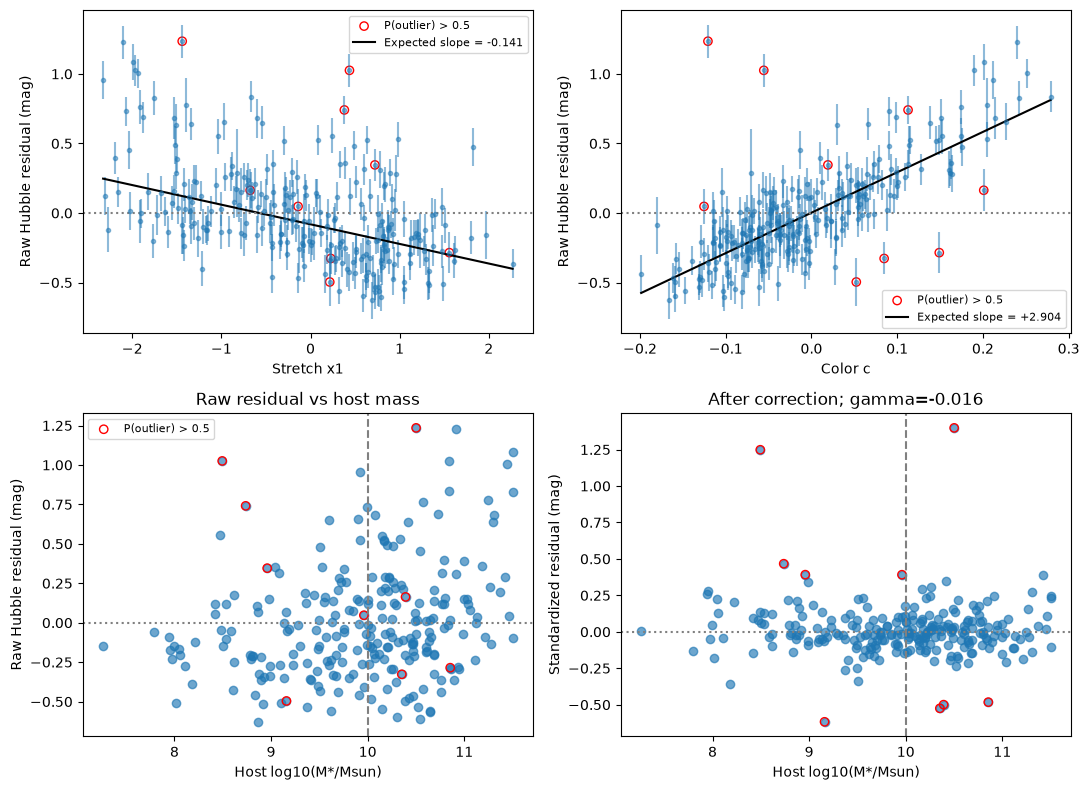

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import emcee

from scipy.special import expit
from astropy.cosmology import FlatLambdaCDM

# ============================================================
# 1. Load data
# ============================================================


mB = df["mB"].to_numpy(float)
x1 = df["x1"].to_numpy(float)
c = df["c"].to_numpy(float)
z = df["z"].to_numpy(float)
logMhost = df["host_logmass"].to_numpy(float)

names = (
    df["name"].astype(str).to_numpy()
    if "name" in df.columns
    else np.array([str(i) for i in range(len(df))])
)

N = len(df)
H = (logMhost > 10).astype(float)

# Flat Lambda-CDM distance modulus
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
mu = cosmo.distmod(z).value

# Peculiar velocity uncertainty, converted to magnitude
c_light = 299792.458  # km/s
sig_pec = (5 / np.log(10)) * 250.0 / (c_light * z)

# ============================================================
# 2. Build SALT2 covariance matrices
# ============================================================
C = np.zeros((N, 3, 3))

C[:, 0, 0] = df["mB_err"].to_numpy(float)**2
C[:, 1, 1] = df["x1_err"].to_numpy(float)**2
C[:, 2, 2] = df["c_err"].to_numpy(float)**2

C[:, 0, 1] = C[:, 1, 0] = df["cov_mB_x1"].to_numpy(float)
C[:, 0, 2] = C[:, 2, 0] = df["cov_mB_c"].to_numpy(float)
C[:, 1, 2] = C[:, 2, 1] = df["cov_x1_c"].to_numpy(float)

print(f"Number of supernovae: {N}")
print(f"High-mass hosts (logM > 10): {int(H.sum())}")

# ============================================================
# 3. Prior table
# ============================================================
prior_table = pd.DataFrame([
    ["M", "Normal(-19.3, 1.0^2) mag",
     "Broad prior on absolute magnitude."],
    ["alpha", "Normal(0.14, 0.10^2)",
     "Allows uncertainty in the stretch correction."],
    ["beta", "Normal(3.0, 1.5^2)",
     "Allows a broad range of color corrections."],
    ["gamma", "Normal(0, 0.2^2) mag",
     "Allows the mass step to be zero or nonzero."],
    ["sigma_int", "Half-Normal(scale=0.2 mag)",
     "Intrinsic scatter must be positive."],
    ["f", "Beta(1, 19)",
     "Favors a small outlier fraction."],
    ["Delta", "Half-Normal(scale=2 mag), truncated at 4",
     "Contaminants are expected to be fainter."],
    ["s_out", "Half-Normal(scale=0.5 mag), truncated",
     "Allows additional scatter among outliers."]
], columns=["Parameter", "Prior", "Justification"])

print("\n=== PRIOR TABLE ===")
print(prior_table.to_string(index=False))

# ============================================================
# 4. Parameters and likelihood
#
# p = [M, alpha, beta, gamma, ln_sigma_int,
#      logit_f, Delta, ln_s_out]
#
# Tripp residual: mB + alpha*x1 - beta*c - mu - gamma*H
# Therefore v = (1, alpha, -beta).
# ============================================================
def unpack(p):
    M, alpha, beta, gamma, ln_si, logit_f, Delta, ln_so = p
    return M, alpha, beta, gamma, np.exp(ln_si), expit(logit_f), Delta, np.exp(ln_so)


def covariance_term(alpha, beta):
    # Expanded v.T @ C_i @ v, with v=(1, alpha, -beta)
    return (
        C[:, 0, 0]
        + alpha**2 * C[:, 1, 1]
        + beta**2 * C[:, 2, 2]
        + 2 * alpha * C[:, 0, 1]
        - 2 * beta * C[:, 0, 2]
        - 2 * alpha * beta * C[:, 1, 2]
    )


def residual_and_variance(p):
    M, alpha, beta, gamma, sigma_int, f, Delta, s_out = unpack(p)

    r = mB + alpha*x1 - beta*c - mu - gamma*H

    var = (
        covariance_term(alpha, beta)
        + sig_pec**2
        + sigma_int**2
    )

    return r, var


def log_likelihood(p):
    M, alpha, beta, gamma, sigma_int, f, Delta, s_out = unpack(p)
    r, var = residual_and_variance(p)

    if not np.all(np.isfinite(var)) or np.any(var <= 0):
        return -np.inf

    # Ordinary SN Ia component
    log_good = (
        np.log1p(-f)
        - 0.5*np.log(2*np.pi*var)
        - 0.5*(r-M)**2/var
    )

    # Fainter outlier component
    var_out = var + s_out**2
    log_bad = (
        np.log(f)
        - 0.5*np.log(2*np.pi*var_out)
        - 0.5*(r-M-Delta)**2/var_out
    )

    # Log of the mixture, evaluated stably
    from scipy.special import logsumexp
    return np.sum(logsumexp(np.vstack([log_good, log_bad]), axis=0))


# ============================================================
# 5. Log-prior
# ============================================================
def log_prior(p):
    M, alpha, beta, gamma, ln_si, logit_f, Delta, ln_so = p
    sigma_int = np.exp(ln_si)
    f = expit(logit_f)
    s_out = np.exp(ln_so)

    if not np.all(np.isfinite(p)):
        return -np.inf

    if not (0.001 < sigma_int < 1.0):
        return -np.inf
    if not (0.001 < f < 0.5):
        return -np.inf
    if not (0.0 < Delta < 4.0):
        return -np.inf
    if not (0.01 < s_out < 2.0):
        return -np.inf

    # Normal priors; constants independent of parameters omitted
    lp = -0.5*((M + 19.3)/1.0)**2
    lp += -0.5*((alpha - 0.14)/0.10)**2
    lp += -0.5*((beta - 3.0)/1.5)**2
    lp += -0.5*(gamma/0.2)**2

    # Half-normal sigma_int prior and log-transform Jacobian
    lp += -0.5*(sigma_int/0.2)**2 + ln_si

    # Beta(1,19) prior on f, transformed to logit(f)
    lp += 18*np.log1p(-f) + np.log(f) + np.log1p(-f)

    # Half-normal prior on Delta, truncated to (0,4)
    lp += -0.5*(Delta/2.0)**2

    # Half-normal prior on s_out and log-transform Jacobian
    lp += -0.5*(s_out/0.5)**2 + ln_so

    return lp


def log_posterior(p):
    lp = log_prior(p)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(p)


# ============================================================
# 6. Run MCMC
# ============================================================
ndim = 8
nwalkers = 40
burnin = 3000
production = 6000

# Initialize walkers near plausible values
rng = np.random.default_rng(42)
center = np.array([
    -19.3, 0.14, 3.0, -0.05,
    np.log(0.10), np.log(0.05/0.95),
    1.0, np.log(0.4)
])

scales = np.array([
    0.03, 0.015, 0.15, 0.025,
    0.10, 0.25, 0.15, 0.15
])

p0 = center + scales*rng.normal(size=(nwalkers, ndim))

# Ensure all initial walkers are in valid prior support
for j in range(nwalkers):
    attempts = 0
    while not np.isfinite(log_posterior(p0[j])):
        p0[j] = center + scales*rng.normal(size=ndim)
        attempts += 1
        if attempts > 10000:
            raise RuntimeError("Could not initialize valid walkers.")

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

print("\nRunning burn-in...")
state = sampler.run_mcmc(p0, burnin, progress=True)

sampler.reset()
print("\nRunning production chain...")
sampler.run_mcmc(state, production, progress=True)

# Flatten chain after burn-in
samples = sampler.get_chain(flat=True)

# Convert sampled parameters to physical parameters
samples_phys = samples.copy()
samples_phys[:, 4] = np.exp(samples[:, 4])  # sigma_int
samples_phys[:, 5] = expit(samples[:, 5])   # f
samples_phys[:, 7] = np.exp(samples[:, 7])  # s_out

param_names = [
    "M", "alpha", "beta", "gamma",
    "sigma_int", "f_outlier", "Delta", "s_out"
]

# ============================================================
# 7. Print posterior estimates and credible intervals
# ============================================================
print("\n=== POSTERIOR RESULTS: median and 68% credible interval ===")

for j, name in enumerate(param_names):
    q16, q50, q84 = np.percentile(
        samples_phys[:, j], [16, 50, 84]
    )
    print(f"{name:12s} = {q50:+.4f} (+{q84-q50:.4f}/-{q50-q16:.4f})")

gamma_samples = samples_phys[:, 3]
print("\n=== HOST-MASS STEP ===")
print(f"Posterior median gamma = {np.median(gamma_samples):+.4f} mag")
print(f"P(gamma < 0) = {np.mean(gamma_samples < 0):.4f}")
print(f"P(gamma > 0) = {np.mean(gamma_samples > 0):.4f}")

# MCMC diagnostics
print("\n=== MCMC DIAGNOSTICS ===")
print(f"Mean acceptance fraction: {np.mean(sampler.acceptance_fraction):.3f}")

try:
    tau = sampler.get_autocorr_time()
    print("Autocorrelation times:")
    for name, t in zip(param_names, tau):
        print(f"  {name:12s}: {t:.1f}")
except Exception as exc:
    print("Autocorrelation time not reliably estimated:", exc)

# ============================================================
# 8. Posterior outlier probabilities
# ============================================================
p_median = np.median(samples, axis=0)
r, var = residual_and_variance(p_median)
M_fit, alpha_fit, beta_fit, gamma_fit, sigma_int_fit, f_fit, Delta_fit, s_out_fit = unpack(p_median)

log_good = (
    np.log1p(-f_fit)
    - 0.5*np.log(2*np.pi*var)
    - 0.5*(r-M_fit)**2/var
)
var_out = var + s_out_fit**2
log_bad = (
    np.log(f_fit)
    - 0.5*np.log(2*np.pi*var_out)
    - 0.5*(r-M_fit-Delta_fit)**2/var_out
)

# Probability of outlier membership, conditional on fitted parameters
from scipy.special import expit
p_out = expit(log_bad - log_good)

outlier_table = pd.DataFrame({
    "name": names,
    "z": z,
    "raw_residual_mag": r - M_fit,
    "P_outlier": p_out
}).sort_values("P_outlier", ascending=False)

print("\n1. EXPANDED VARIANCE")
print("""
Using v = (1, alpha, -beta):

v.T @ C_i @ v =
    sigma_mB^2
    + alpha^2 * sigma_x1^2
    + beta^2 * sigma_c^2
    + 2*alpha * cov(mB, x1)
    - 2*beta * cov(mB, c)
    - 2*alpha*beta * cov(x1, c)

Total variance:
sigma_i^2 = v.T @ C_i @ v
            + sigma_mu_pec_i^2
            + sigma_int^2

Off-diagonal terms appear because measurement errors are correlated.
""")

# 2. Log-likelihood
print("\n2. LOG-LIKELIHOOD")
print("""
r_i = mB_i + alpha*x1_i - beta*c_i
      - mu(z_i) - gamma*H_i

log L = -0.5 * sum_i [
    log(2*pi*sigma_i^2)
    + (r_i - M)^2 / sigma_i^2
]

The log(sigma_i^2) term is required because the variance
depends on the fitted parameters.
""")

# 3. Prior table
priors = [
    ["M", "Normal(-19.3, 1.0^2) mag",
     "Broad prior for SN Ia absolute magnitude."],
    ["alpha", "Normal(0.14, 0.10^2)",
     "Allows uncertainty in the stretch correction."],
    ["beta", "Normal(3.0, 1.5^2)",
     "Allows a broad range of color corrections."],
    ["gamma", "Normal(0, 0.2^2) mag",
     "Allows the host-mass step to be zero or nonzero."],
    ["sigma_int", "Half-Normal(scale=0.2 mag)",
     "Intrinsic scatter must be positive."],
    ["f", "Beta(1, 19)",
     "Favors a small contaminant fraction."],
    ["Delta", "Half-Normal(scale=2 mag), truncated at 4",
     "Contaminants are expected to be fainter."],
    ["s_out", "Half-Normal(scale=0.5 mag)",
     "Allows additional scatter among contaminants."]
]

print("\n3. PRIOR TABLE")
print(pd.DataFrame(
    priors,
    columns=["Parameter", "Prior", "Justification"]
).to_string(index=False))

# 4. Sampling and contaminants
print("\n4. SAMPLING CHOICE")
print("Sample ln(sigma_int) to guarantee sigma_int > 0.")
print("Include the Jacobian if the prior is specified on sigma_int.")

print("\n5. CONTAMINANTS")
print("Use a two-component mixture model and calculate posterior")
print("outlier probabilities. A hard cut reduces sample size and")
print("statistical power and may introduce selection bias.")

print(f"\nSum of outlier probabilities: {p_out.sum():.2f}")
print(f"Objects with P(outlier) > 0.5: {(p_out > 0.5).sum()}")

# Save table for your assignment
outlier_table.to_csv("sne_outlier_probabilities.csv", index=False)

# ============================================================
# 9. Plot raw and standardized Hubble residuals
# ============================================================
r0 = mB - mu - M_fit
rstd = mB + alpha_fit*x1 - beta_fit*c - mu - M_fit - gamma_fit*H

sig_plot = np.sqrt(var)
is_out = p_out > 0.5

fig, axs = plt.subplots(2, 2, figsize=(11, 8))

for ax, x, label, slope in [
    (axs[0, 0], x1, "Stretch x1", -alpha_fit),
    (axs[0, 1], c, "Color c", beta_fit)
]:
    ax.errorbar(x, r0, yerr=sig_plot, fmt=".", alpha=0.5)
    ax.scatter(x[is_out], r0[is_out], facecolors="none",
               edgecolors="red", label="P(outlier) > 0.5")
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(xx, np.median(r0[~is_out]) + slope*(xx-np.median(x[~is_out])),
            "k-", label=f"Expected slope = {slope:+.3f}")
    ax.axhline(0, color="gray", linestyle=":")
    ax.set_xlabel(label)
    ax.set_ylabel("Raw Hubble residual (mag)")
    ax.legend(fontsize=8)

ax = axs[1, 0]
ax.scatter(logMhost, r0, alpha=0.65)
ax.scatter(logMhost[is_out], r0[is_out], facecolors="none",
           edgecolors="red", label="P(outlier) > 0.5")
ax.axvline(10, color="gray", linestyle="--")
ax.axhline(0, color="gray", linestyle=":")
ax.set_xlabel("Host log10(M*/Msun)")
ax.set_ylabel("Raw Hubble residual (mag)")
ax.set_title("Raw residual vs host mass")
ax.legend(fontsize=8)

ax = axs[1, 1]
ax.scatter(logMhost, rstd, alpha=0.65)
ax.scatter(logMhost[is_out], rstd[is_out], facecolors="none",
           edgecolors="red")
ax.axvline(10, color="gray", linestyle="--")
ax.axhline(0, color="gray", linestyle=":")
ax.set_xlabel("Host log10(M*/Msun)")
ax.set_ylabel("Standardized residual (mag)")
ax.set_title(f"After correction; gamma={gamma_fit:+.3f}")

plt.tight_layout()
plt.savefig("sne_mcmc_results.png", dpi=150)
plt.show()

**ANSWER:**

*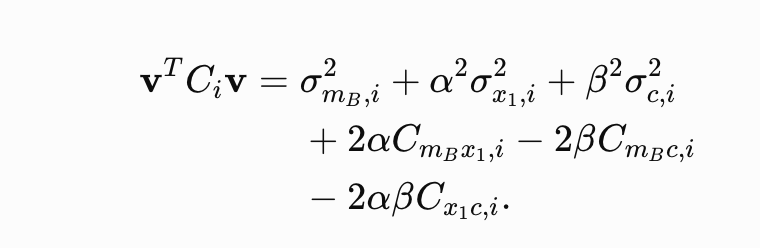 


### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

In [21]:
import numpy as np
import emcee
import arviz as az
import corner
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import expit, logit

# ============================================================
# 1. Parameter setup
# ============================================================
param_names = [
    "M", "alpha", "beta", "gamma",
    "sigma_int", "f_outlier", "Delta", "s_out"
]

ndim = 8
nwalkers = 32
burnin = 3000
ndraws = 5000

# Parameters are sampled in transformed space:
# [M, alpha, beta, gamma, ln_sigma_int, logit_f, Delta, ln_s_out]

initial_center = np.array([
    -19.3, 0.14, 3.0, -0.05,
    np.log(0.10), logit(0.05), 1.0, np.log(0.4)
])

# Broad initial spread, deliberately wider than expected
# posterior uncertainties. All initial walkers must satisfy priors.
start_scales = np.array([
    0.30, 0.08, 0.60, 0.12,
    0.35, 0.90, 0.70, 0.45
])

# ============================================================
# 2. Find the MAP (maximum a posteriori) point
# ============================================================
bounds = [
    (None, None), (None, None), (None, None), (None, None),
    (np.log(0.001), np.log(1.0)),
    (logit(0.001), logit(0.499)),
    (1e-6, 4.0),
    (np.log(0.010), np.log(2.0))
]

rng = np.random.default_rng(2026)

def negative_log_posterior(p):
    lp = log_posterior(p)
    return -lp if np.isfinite(lp) else 1e100

map_result = None

# Multiple starts reduce the chance of finding a poor local optimum.
for j in range(8):
    start = initial_center.copy()
    if j > 0:
        start += rng.normal(size=ndim) * start_scales * 0.35

    result = minimize(
        negative_log_posterior,
        start,
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": 20000, "ftol": 1e-12}
    )

    if result.success and np.isfinite(result.fun):
        if map_result is None or result.fun < map_result.fun:
            map_result = result

if map_result is None:
    raise RuntimeError(
        "MAP optimization failed. Try additional starting points."
    )

map_est = map_result.x

def to_physical(p):
    q = p.copy()
    q[4] = np.exp(p[4])
    q[5] = expit(p[5])
    q[7] = np.exp(p[7])
    return q

map_phys = to_physical(map_est)

print("\n=== MAXIMUM A POSTERIORI (MAP) ===")
print(f"Log posterior = {-map_result.fun:.4f}")

for name, value in zip(param_names, map_phys):
    print(f"{name:12s} = {value:+.5f}")

# ============================================================
# 3. Four independent ensemble runs
# ============================================================
all_chains = []
all_walkers = []

for chain_id in range(4):
    print(f"\nRunning independent chain {chain_id + 1}/4")

    # Each ensemble begins independently, with a broad spread
    # around the MAP rather than being initialized at the same point.
    p0 = map_est + rng.normal(
        size=(nwalkers, ndim)
    ) * start_scales

    # Keep all initial walkers inside the prior support.
    for w in range(nwalkers):
        attempts = 0
        while not np.isfinite(log_posterior(p0[w])):
            p0[w] = map_est + rng.normal(size=ndim) * start_scales
            attempts += 1
            if attempts > 10000:
                raise RuntimeError("Could not initialize walkers.")

    sampler = emcee.EnsembleSampler(
        nwalkers, ndim, log_posterior
    )

    state = sampler.run_mcmc(p0, burnin, progress=True)
    sampler.reset()
    sampler.run_mcmc(state, ndraws, progress=True)

    # Store all walkers for posterior summaries and the corner plot.
    chain = sampler.get_chain()  # (draw, walker, parameter)
    all_walkers.append(chain)

    # Select one walker trajectory from each independent ensemble
    # for cross-chain convergence diagnostics.
    selected_walker = chain[:, chain_id, :]
    all_chains.append(selected_walker)

    print(
        "Mean acceptance fraction:",
        round(np.mean(sampler.acceptance_fraction), 3)
    )

# Shape for ArviZ: (chain, draw, parameter)
chains = np.stack(all_chains, axis=0)

# Pool all walkers from all four ensembles for posterior estimates.
pooled = np.concatenate(
    [ch.reshape(-1, ndim) for ch in all_walkers],
    axis=0
)

# Convert to physical parameters.
pooled_phys = pooled.copy()
pooled_phys[:, 4] = np.exp(pooled[:, 4])
pooled_phys[:, 5] = expit(pooled[:, 5])
pooled_phys[:, 7] = np.exp(pooled[:, 7])

# ============================================================
# 4. R-hat, effective sample size, and posterior summary
# ============================================================
chains_phys = chains.copy()
chains_phys[:, :, 4] = np.exp(chains[:, :, 4])
chains_phys[:, :, 5] = expit(chains[:, :, 5])
chains_phys[:, :, 7] = np.exp(chains[:, :, 7])

idata = az.from_dict({
    "posterior": {
        name: chains_phys[:, :, i]
        for i, name in enumerate(param_names)
    }
})

diagnostics = az.summary(
    idata,
    var_names=param_names,
    kind="all",
    hdi_prob=0.68,
    round_to=4
)

print("\n=== CONVERGENCE DIAGNOSTICS ===")
print(diagnostics.to_string())

print("""
Interpretation:
  R-hat < 1.01 is a good target.
  Bulk ESS and tail ESS should ideally both exceed 400
  for each parameter, with more samples preferred for
  precise tail probabilities.
  Run longer if R-hat is high, ESS is low, or chains
  have not mixed across the posterior.
""")

# ============================================================
# 5. Report M, alpha, beta, gamma as median and 16-84% interval
# ============================================================
print("\n=== POSTERIOR MEDIANS AND 16th-84th PERCENTILES ===")

for name in ["M", "alpha", "beta", "gamma"]:
    j = param_names.index(name)
    q16, q50, q84 = np.percentile(
        pooled_phys[:, j], [16, 50, 84]
    )
    print(
        f"{name:8s} = {q50:+.5f} "
        f"(+{q84-q50:.5f}/-{q50-q16:.5f})"
    )

# ============================================================
# 6. Corner plot
# ============================================================
fig = corner.corner(
    pooled_phys,
    labels=param_names,
    quantiles=[0.16, 0.50, 0.84],
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 9}
)

fig.savefig("sne_corner.png", dpi=160, bbox_inches="tight")
plt.show()

print("\nSaved corner plot as sne_corner.png")

# ============================================================
# 7. Strong parameter correlations
# ============================================================
corr = np.corrcoef(pooled_phys, rowvar=False)

pairs = []
for i in range(ndim):
    for j in range(i + 1, ndim):
        pairs.append((
            abs(corr[i, j]),
            param_names[i],
            param_names[j],
            corr[i, j]
        ))

pairs.sort(reverse=True)

print("\n=== STRONGEST POSTERIOR CORRELATIONS ===")
for strength, a, b, value in pairs[:8]:
    print(f"{a:12s} vs {b:12s}: r = {value:+.3f}")

# ============================================================
# 8. Fix alpha at its MAP value and refit beta
# ============================================================
alpha_map = map_est[1]

def fixed_alpha_objective(q):
    p = q.copy()
    p[1] = alpha_map
    return negative_log_posterior(p)

free_indices = [i for i in range(ndim) if i != 1]
start_fixed = map_est[free_indices]

bounds_fixed = [bounds[i] for i in free_indices]

fixed_result = minimize(
    fixed_alpha_objective,
    start_fixed,
    method="L-BFGS-B",
    bounds=bounds_fixed,
    options={"maxiter": 20000, "ftol": 1e-12}
)

p_fixed = map_est.copy()
p_fixed[1] = alpha_map
p_fixed[free_indices] = fixed_result.x

beta_fixed = p_fixed[2]
beta_marginal = np.median(pooled_phys[:, 2])

q16, q50, q84 = np.percentile(
    pooled_phys[:, 2], [16, 50, 84]
)

print("\n=== FIXED-ALPHA COMPARISON ===")
print(f"Fixed alpha at MAP = {alpha_map:.5f}")
print(f"Beta at fixed-alpha MAP = {beta_fixed:.5f}")
print(
    f"Marginal beta = {beta_marginal:.5f} "
    f"(+{q84-q50:.5f}/-{q50-q16:.5f})"
)
print(f"Difference = {beta_fixed - beta_marginal:+.5f}")


=== MAXIMUM A POSTERIORI (MAP) ===
Log posterior = 122.2795
M            = -19.29243
alpha        = +0.14035
beta         = +2.90369
gamma        = -0.01597
sigma_int    = +0.07370
f_outlier    = +0.06381
Delta        = +0.15218
s_out        = +0.53615

Running independent chain 1/4


100%|██████████████████████████████████████| 5000/5000 [00:37<00:00, 133.44it/s]


Mean acceptance fraction: 0.443

Running independent chain 2/4


100%|██████████████████████████████████████| 5000/5000 [00:38<00:00, 128.75it/s]


Mean acceptance fraction: 0.443

Running independent chain 3/4


100%|██████████████████████████████████████| 5000/5000 [00:39<00:00, 127.79it/s]


Mean acceptance fraction: 0.437

Running independent chain 4/4


100%|██████████████████████████████████████| 5000/5000 [00:37<00:00, 134.33it/s]


Mean acceptance fraction: 0.441


TypeError: summary() got an unexpected keyword argument 'hdi_prob'. Did you mean 'ci_prob'?

In [ ]:
# 2c: your work here
# used nested sampling 


**ANSWER:**

**

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [ ]:
# 2d: your work here

**ANSWER:**

*your answer goes here*

### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

In [ ]:
# 2e: your work here

**ANSWER:**

*your answer goes here*

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

In [ ]:
# 3a: your work here


**REFEREE REPORT:**

*your report goes here*

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**

*I used ChatBGT*

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.